# An Illustrative Example

1. Objectives
2. Theory and Examples
   1. Problem Statement
   2. Perceptron
      - Two-Input Case
      - Pattern Recognition Example
   3. Hamming Network
      - Feedforward Layer
      - Recurrent Layer
   4. Hopfield Network
4. Epilogue
5. Exercises

# Objectives

Think of this chapter as a preview of coming attractions. We will **take a 
simple pattern recognition problem and show how it can be solved using 
three different neural network architectures**. It will be an opportunity $\textbf{to 
see how the architectures described in the previous chapter can be used to 
solve a practical }$(although extremely oversimplified) **problem**. <u>*Do not expect to completely understand these three networks after reading this 
chapter*</u>. We present them simply to give you a taste of what can be done 
with neural networks, and to demonstrate that there are many different 
types of networks that can be used to solve a given problem.

The **three networks presented in this chapter are representative of the 
types of networks** discussed in the **remaining chapters**: feedforward net
works (represented here by the perceptron), competitive networks (represented here by the Hamming network) and recurrent associative memory networks (represented here by the Hopfield network).

1. Feedforword network == Perceptron
2. Competitive newtork == Hamming Network
3. Recurrent Associative Memory Network == Hopfield Network

# Theory and Examples

## Problem Statement

A produce dealer has a warehouse that stores a variety of fruits and vegetables. When fruit is brought to the warehouse, various types of fruit may be mixed together. The dealer wants a machine that will sort the fruit according to type. There is a conveyer belt on which the fruit is loaded.

> This conveyer passes through a set of sensors, **which measure three properties 
of the fruit: shape, texture and weight**. These sensors are somewhat primitive.

- The shape sensor will output a = 1. if, the fruit is approximately round and a = -1. if, it is more elliptical. 
- The texture sensor will output a = 1. if, the surface of the fruit is smooth and a = -1. if, it is rough. 
- The weight sensor will output a = 1. if, the fruit is more than one pound and a = -1. if, it is less than one pound.

As each fruit passes through the sensors it can be represented by a three
dimensional vector. The first element of the vector will represent shape, 
the second element will represent texture and the third element will represent weight:



$$\LARGE \mathbf{p} = \begin{bmatrix} shape \\ texture \\ weight \end{bmatrix}. \tag{3.1}$$

Therefore, a prototype **orange** would be represented by

$$\LARGE \mathbf{p} = \begin{bmatrix} 1 \\ -1 \\ -1 \end{bmatrix}. \tag{3.2}$$

and a prototype **apple** would be represented by


$$\LARGE \mathbf{p} = \begin{bmatrix} 1 \\ 1 \\ -1 \end{bmatrix}. \tag{3.3}$$

The neural network will receive one three-dimensional input vector for 
each fruit on the conveyer and must make a decision as to whether the fruit 
is an **orange** ($p_1$)  or an **apple** ($p_2$).

Now that we have defined this simple (trivial?) pattern recognition problem, let’s look briefly at three different neural networks that could be used to solve it. The simplicity of our problem will facilitate our understanding of the operation of the networks.

## Perceptron

The first network we will discuss is the perceptron. Figure 3.1 illustrates a 
**single-layer perceptron with a symmetric hard limit transfer function hardlims**.


![](images/single_layer_perceptron.jpeg)

### Two-Input Case

Before we use the perceptron to solve the orange and apple recognition 
problem (which will require a three-input perceptron, i.e., R = 3), it is useful to investigate the capabilities of a two-input/single-neuron perceptron (R = 2 ), which can be easily analyzed graphically. The two-input perceptron is shown in Figure 3.2.

![](images/two_input_snp.jpeg)

Single-neuron perceptrons can classify input vectors into two categories. 
For example, for a two-input perceptron, if $w_{1,1} = -1$  and $w_{1,2} = 1$  then

$$a = hardlims(n) = hardlims(\begin{bmatrix}-1 & 1\end{bmatrix} \textbf{p} + b) \tag{3.4}.$$

Therefore, if the inner product of the weight matrix (a single row vector in 
this case) with the input vector is greater than or equal to , the output 
will be 1. If the inner product of the weight vector and the input is less than -b, the output will be -1. This divides the input space into two parts. Figure 3.3 illustrates this for the case where b = -1 . The blue line in the figure represents all points for which the net input n is equal to 0:

$$n = \begin{bmatrix}-1 & 1\end{bmatrix}\textbf{p} - 1 = 0 \tag{3.5}$$

**Notice that this decision boundary will always be orthogonal to the weight 
matrix, and the position of the boundary can be shifted by changing** . (In 
the general case,  is a matrix consisting of a number of row vectors, each 
of which will be used in an equation like Eq. (3.5). There will be one boundary for each row of . See **Chapter 4 for more on this topic.**) <u>The shaded 
region contains all input vectors for which the output of the network will be 1</u>. The output will be  for all other input vectors.




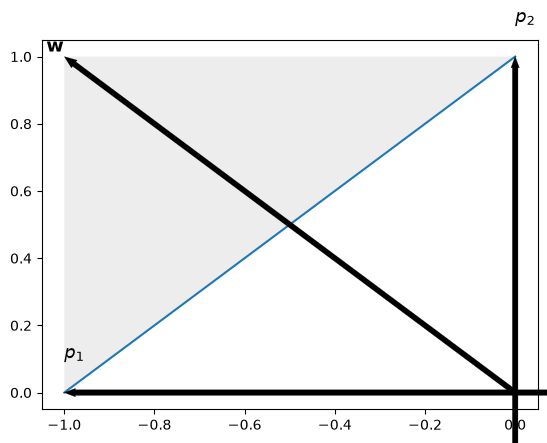

In [140]:
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.subplots()
ax.plot([-1,0], [0,1])

# Fill the region n > 0 (to the left/above the line)
p2_shade = np.linspace(0.0, 1.0, 100)
ax.fill_betweenx(p2_shade, -1, p2_shade - 1, color='lightgray', alpha=0.4, edgecolor='none')

# --- 4. Weight Vector w ---
ax.annotate(
    '', xy=(-1, 1), xytext=(0, 0),arrowprops=dict(facecolor='black', edgecolor='black', lw=0.1, headwidth=7, headlength=9)
)
ax.text(-1, 1, r'$\mathbf{w}$', fontsize=14, fontweight='bold', ha='right', va='bottom')


# --- 1. Draw Custom Axes with Arrows ---
ax.annotate(
    '', xy=(-1.0, 0), xytext=(1.0, 0),
    arrowprops=dict(facecolor='black', edgecolor='black', lw=0.2, headwidth=6, headlength=8)
)

ax.annotate(
    '', xy=(0, 1.0), xytext=(0, -1.0),
    arrowprops=dict(facecolor='black', edgecolor='black', lw=0.2, headwidth=6, headlength=8)
)

# Axis labels
ax.text(-1.0, 0.1, '$p_1$', fontsize=13, fontstyle='italic')
ax.text(0.0, 1.10, '$p_2$', fontsize=13, fontstyle='italic')


plt.show()


The key property of the single-neuron perceptron, therefore, is that it can 
separate input vectors into two categories. The decision boundary between 
the categories is determined by the equation

$$\textbf{Wp} + b = 0.\tag{3.6}$$

Because the boundary must be linear, the single-layer perceptron can only 
be used to recognize patterns that are linearly separable (can be separated 
by a linear boundary). These concepts will be discussed in more detail in 
Chapter 4.

### Pattern Recognition Example

Now consider the apple and orange pattern recognition problem. Because 
there are only two categories, we can use a single-neuron perceptron. The 
vector inputs are three-dimensional (R=3), therefore the perceptron equation will be 

$$\LARGE a = \operatorname{hardlims}\left( \begin{bmatrix} w_{1,1} & w_{1,2} & w_{1,3}\end{bmatrix}\begin{bmatrix}p_1 \\ p_2 \\ p_3 \end{bmatrix} + b \right) \tag{3.7}$$

We want to choose the bias  and the elements of the weight matrix so that 
the perceptron will be able to distinguish between apples and oranges. For 
example, we may want the output of the perceptron to be 1 when an apple 
is input and -1 when an orange is input. Using the concept illustrated in 
Figure 3.3, let’s find a linear boundary that can separate oranges and apples. The two prototype vectors (recall Eq. (3.2) and Eq. (3.3)) are shown in Figure 3.4. From this figure we can see that the linear boundary that divides these two vectors symmetrically is the $p_1, p_2$ plane.

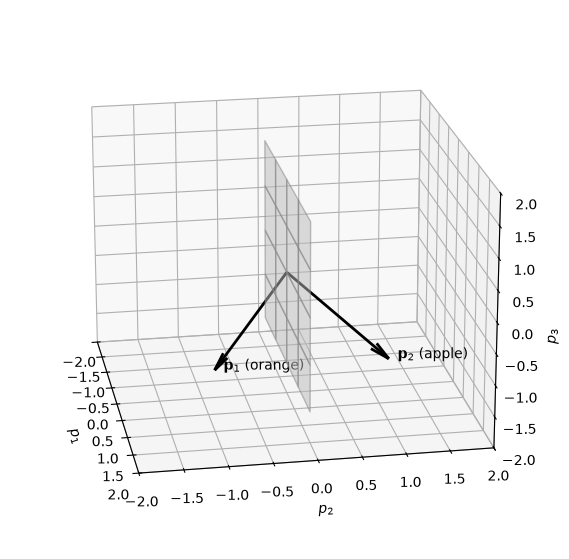

In [147]:
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection='3d')

# Prototype vectors from the textbook
p1 = np.array([1, -1, -1])  # p1 = 1, p2 = -1, p3 = -1 (orange)[cite: 2]
p2 = np.array([1, 1, -1])   # p1 = 1, p2 = 1, p3 = -1[cite: 2]

# 1. Plot vectors with proper arrow heads
ax.quiver(0, 0, 0, p1[0], p1[1], p1[2], color='black', arrow_length_ratio=0.15, linewidth=2)
ax.quiver(0, 0, 0, p2[0], p2[1], p2[2], color='black', arrow_length_ratio=0.15, linewidth=2)

# Vector labels
ax.text(p1[0], p1[1], p1[2], r'  $\mathbf{p}_1$ (orange)', fontsize=10)
ax.text(p2[0], p2[1], p2[2], r'  $\mathbf{p}_2$ (apple)', fontsize=10)

# 2. Decision boundary plane ($p_2 = 0$)
xx, zz = np.meshgrid(np.linspace(-1.5, 1.5, 5), np.linspace(-1.5, 1.5, 5))
yy = np.zeros_like(xx)
ax.plot_surface(xx, yy, zz, color='lightgray', alpha=0.5, edgecolor='gray')

# 3. Axis setup and matching textbook perspective
ax.set_xlabel('$p_1$')
ax.set_ylabel('$p_2$')
ax.set_zlabel('$p_3$')

ax.set_xlim([-2, 2])
ax.set_ylim([-2, 2])
ax.set_zlim([-2, 2])

# Rotate camera to match Figure 3.4
ax.view_init(elev=20, azim=-10)

plt.show()

The $p_1,p_3$ plane, which will be our decision boundary, can be described by 
the equation

$$\LARGE p_2 = 0, \tag{3.8}$$

or

$$\begin{bmatrix}0 & 1 & 0 \end{bmatrix} \begin{bmatrix}p_1 \\ p_2 \\ p_3 \end{bmatrix} + 0 = 0 \tag{3.9}$$

Therefore the weight matrix and bias will be

$$\textbf{W} = \begin{bmatrix}0 & 1 & 0 \end{bmatrix}, b = 0 \tag{3.10} $$


The weight matrix is orthogonal to the decision boundary and points toward the region that contains the prototype pattern $p_2$ (apple) for which we want the perceptron to produce an output of 1. The bias is 0 because the decision boundary passes through the origin.

Now let’s test the operation of our perceptron pattern classifier. It classifies 
perfect apples and oranges correctly since

### Orange:

$$\LARGE a = \operatorname{hardlims}\left( \begin{bmatrix} 0 & 1 & 0\end{bmatrix}\begin{bmatrix}1 \\ -1 \\ -1 \end{bmatrix} + 0 \right) = -1 (orange) \tag{3.11}$$

### Apple:

$$\LARGE a = \operatorname{hardlims}\left( \begin{bmatrix} 0 & 1 & 0\end{bmatrix}\begin{bmatrix}1 \\ 1 \\ -1 \end{bmatrix} + 0 \right) = 1 (apple) \tag{3.12}$$

**But what happens if we put a not-so-perfect orange into the classifier**? Let’s 
say that an orange with an elliptical shape is passed through the sensors. 
The input vector would then be


$$\LARGE \mathbf{p} = \begin{bmatrix} -1 \\ -1 \\ -1 \end{bmatrix}. \tag{3.13}$$

The response of the network would be

$$\LARGE a = \operatorname{hardlims}\left( \begin{bmatrix} 0 & 1 & 0\end{bmatrix}\begin{bmatrix}-1 \\ -1 \\ -1 \end{bmatrix} + 0 \right) = -1 (orange) \tag{3.14}$$

In fact, any input vector that is closer to the orange prototype vector than 
to the apple prototype vector (in Euclidean distance) will be classified as an 
orange (and vice versa).


This example has demonstrated some of the features of the perceptron network, but by no means have we exhausted our investigation of perceptrons. This network, and variations on it, will be examined in Chapters 4 through 13. Let’s consider some of these future topics.

In the apple/orange example we were able to design a network graphically, 
by choosing a decision boundary that clearly separated the patterns. What 
about practical problems, with high dimensional input spaces? In Chapters 
4, 7, 10 and 11 we will introduce learning algorithms that can be used to 
train networks to solve complex problems by using a set of examples of 
proper network behavior.

The key characteristic of the single-layer perceptron is that it creates linear 
decision boundaries to separate categories of input vector. What if we have 
categories that cannot be separated by linear boundaries? This question 
will be addressed in Chapter 11, where we will introduce the multilayer 
perceptron. The multilayer networks are able to solve classification prob
lems of arbitrary complexity.


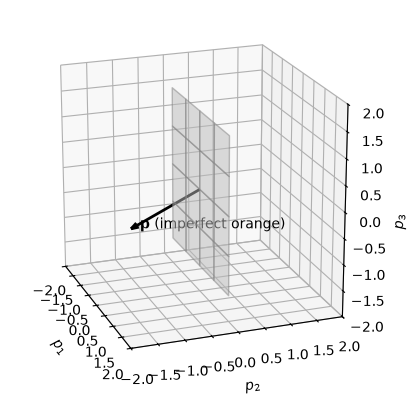

In [2]:
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# Input vector for the imperfect orange
p = np.array([-1, -1, -1])

# Plot vector from origin using quiver
ax.quiver(0, 0, 0, p[0], p[1], p[2], color='black', lw=2, arrow_length_ratio=0.1)

# Vector label (using raw string to avoid escape warnings)
ax.text(p[0], p[1], p[2], r'  $\mathbf{p}$ (imperfect orange)', fontsize=10)

# Decision boundary plane ($p_2 = 0$)
xx, zz = np.meshgrid(np.linspace(-1.5, 1.5, 5), np.linspace(-1.5, 1.5, 5))
yy = np.zeros_like(xx)
ax.plot_surface(xx, yy, zz, color='lightgray', alpha=0.5, edgecolor='gray')

# Axis limits and equal box aspect ratio
ax.set_xlim([-2, 2])
ax.set_ylim([-2, 2])
ax.set_zlim([-2, 2])
ax.set_box_aspect([1, 1, 1])

# Axis labels
ax.set_xlabel('$p_1$')
ax.set_ylabel('$p_2$')
ax.set_zlabel('$p_3$')

ax.view_init(elev=20, azim=-20)
plt.show()

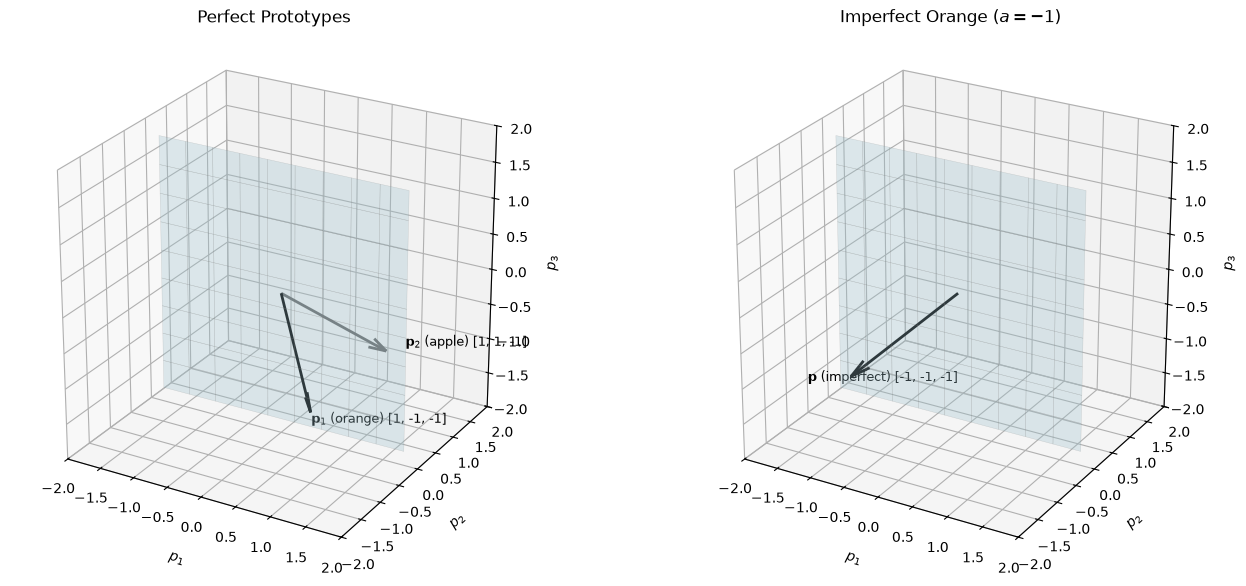

In [163]:
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(figsize=(14, 6))

# Common grid for the decision boundary plane ($p_2 = 0$)
p1_mesh, p3_mesh = np.meshgrid(np.linspace(-1.8, 1.8, 10), np.linspace(-1.8, 1.8, 10))
p2_mesh = np.zeros_like(p1_mesh)

# --- Subplot 1: Perfect Prototypes ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
p1 = np.array([1, -1, -1])  # orange[cite: 2]
p2 = np.array([1, 1, -1])   # apple[cite: 2]

ax1.quiver(0, 0, 0, p1[0], p1[1], p1[2], color='black', lw=2, arrow_length_ratio=0.15)
ax1.quiver(0, 0, 0, p2[0], p2[1], p2[2], color='dimgray', lw=2, arrow_length_ratio=0.15)

# Offset text to prevent overlapping
ax1.text(p1[0] + 0.15, p1[1] - 0.25, p1[2], r'$\mathbf{p}_1$ (orange) [1, -1, -1]', fontsize=9)
ax1.text(p2[0] + 0.15, p2[1] + 0.25, p2[2], r'$\mathbf{p}_2$ (apple) [1, 1, -1]', fontsize=9)

# Semi-transparent decision boundary plane
ax1.plot_surface(p1_mesh, p2_mesh, p3_mesh, color='lightblue', alpha=0.3, edgecolor='gray', linewidth=0.3)

ax1.set_title("Perfect Prototypes", fontsize=12, pad=10)
ax1.set_xlabel('$p_1$', labelpad=8)
ax1.set_ylabel('$p_2$', labelpad=8)
ax1.set_zlabel('$p_3$', labelpad=8)
ax1.set_xlim([-2, 2])
ax1.set_ylim([-2, 2])
ax1.set_zlim([-2, 2])
ax1.set_box_aspect([1, 1, 1])
ax1.view_init(elev=25, azim=-60)


# --- Subplot 2: Imperfect Orange ---
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
p_imp = np.array([-1, -1, -1])  # imperfect orange[cite: 4]

ax2.quiver(0, 0, 0, p_imp[0], p_imp[1], p_imp[2], color='black', lw=2, arrow_length_ratio=0.15)
ax2.text(p_imp[0] - 0.4, p_imp[1] - 0.4, p_imp[2], r'$\mathbf{p}$ (imperfect) [-1, -1, -1]', fontsize=9)

# Semi-transparent decision boundary plane
ax2.plot_surface(p1_mesh, p2_mesh, p3_mesh, color='lightblue', alpha=0.3, edgecolor='gray', linewidth=0.3)

ax2.set_title("Imperfect Orange ($a = -1$)", fontsize=12, pad=10)
ax2.set_xlabel('$p_1$', labelpad=8)
ax2.set_ylabel('$p_2$', labelpad=8)
ax2.set_zlabel('$p_3$', labelpad=8)
ax2.set_xlim([-2, 2])
ax2.set_ylim([-2, 2])
ax2.set_zlim([-2, 2])
ax2.set_box_aspect([1, 1, 1])
ax2.view_init(elev=25, azim=-60)

plt.tight_layout()
plt.show()

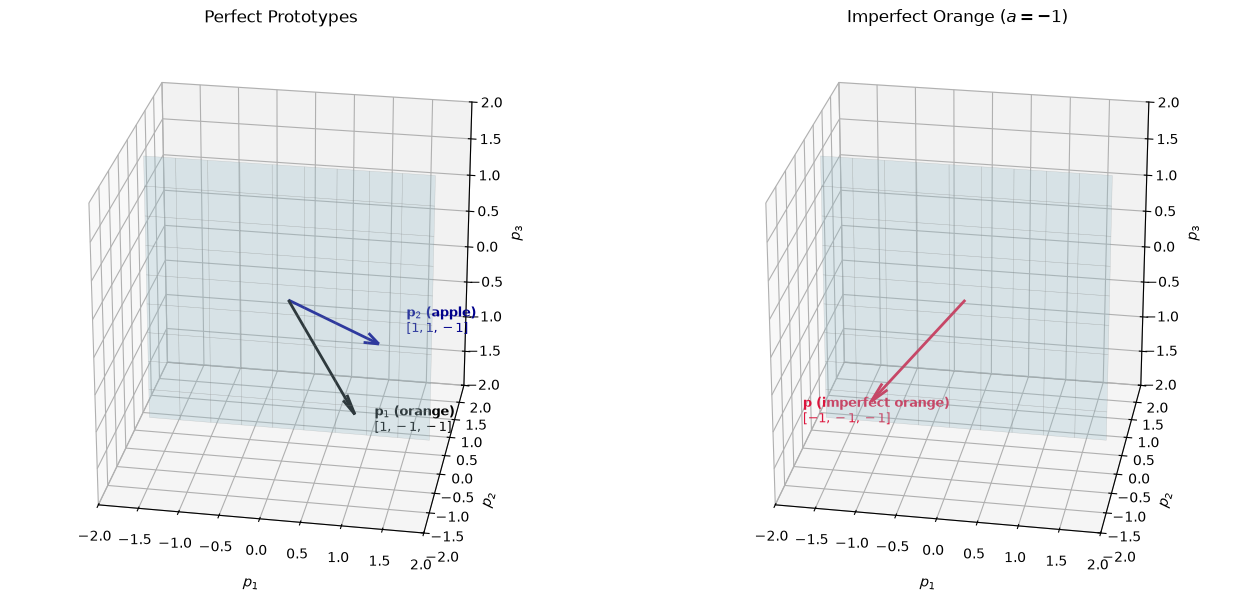

In [6]:
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(figsize=(14, 6))

# Common grid for the decision boundary plane ($p_2 = 0$)
p1_mesh, p3_mesh = np.meshgrid(np.linspace(-1.8, 1.8, 10), np.linspace(-1.8, 1.8, 10))
p2_mesh = np.zeros_like(p1_mesh)

# --- Subplot 1: Perfect Prototypes ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
p1 = np.array([1, -1, -1])  # orange[cite: 2]
p2 = np.array([1, 1, -1])   # apple[cite: 2]

ax1.quiver(0, 0, 0, p1[0], p1[1], p1[2], color='black', lw=2, arrow_length_ratio=0.15)
ax1.quiver(0, 0, 0, p2[0], p2[1], p2[2], color='darkblue', lw=2, arrow_length_ratio=0.15)

# Multi-line clean text placement for visibility
ax1.text(p1[0] + 0.3, p1[1] - 0.4, p1[2], r'$\mathbf{p}_1$ (orange)' + '\n' + '$[1, -1, -1]$', fontsize=9, color='black', fontweight='bold')
ax1.text(p2[0] + 0.3, p2[1] + 0.4, p2[2], r'$\mathbf{p}_2$ (apple)' + '\n' + '$[1, 1, -1]$', fontsize=9, color='darkblue', fontweight='bold')

# Semi-transparent decision boundary plane
ax1.plot_surface(p1_mesh, p2_mesh, p3_mesh, color='lightblue', alpha=0.3, edgecolor='gray', linewidth=0.3)

ax1.set_title("Perfect Prototypes", fontsize=12, pad=10)
ax1.set_xlabel('$p_1$', labelpad=8)
ax1.set_ylabel('$p_2$', labelpad=8)
ax1.set_zlabel('$p_3$', labelpad=8)
ax1.set_xlim([-2, 2])
ax1.set_ylim([-2, 2])
ax1.set_zlim([-2, 2])
ax1.set_box_aspect([1, 1, 1])
ax1.view_init(elev=25, azim=-80)


# --- Subplot 2: Imperfect Orange ---
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
p_imp = np.array([-1, -1, -1])  # imperfect orange[cite: 4]

ax2.quiver(0, 0, 0, p_imp[0], p_imp[1], p_imp[2], color='crimson', lw=2, arrow_length_ratio=0.15)
ax2.text(p_imp[0] - 0.7, p_imp[1] - 0.7, p_imp[2], r'$\mathbf{p}$ (imperfect orange)' + '\n' + '$[-1, -1, -1]$', fontsize=9, color='crimson', fontweight='bold')

# Semi-transparent decision boundary plane
ax2.plot_surface(p1_mesh, p2_mesh, p3_mesh, color='lightblue', alpha=0.3, edgecolor='gray', linewidth=0.3)

ax2.set_title("Imperfect Orange ($a = -1$)", fontsize=12, pad=10)
ax2.set_xlabel('$p_1$', labelpad=8)
ax2.set_ylabel('$p_2$', labelpad=8)
ax2.set_zlabel('$p_3$', labelpad=8)
ax2.set_xlim([-2, 2])
ax2.set_ylim([-2, 2])
ax2.set_zlim([-2, 2])
ax2.set_box_aspect([1, 1, 1])
ax2.view_init(elev=25, azim=-80)

plt.tight_layout()
plt.show()

## Hamming Network

The next network we will consider is the Hamming network [Lipp87]. It 
was designed explicitly to solve binary pattern recognition problems 
(where each element of the input vector has only two possible values — in 
our example 1 or -1). This is an interesting network, because it uses both 
feedforward and recurrent (feedback) layers, which were both described in 
Chapter 2. Figure 3.5 shows the standard Hamming network. Note that 
the number of neurons in the first layer is the same as the number of neurons in the second layer.

The objective of the Hamming network is to decide which prototype vector 
is closest to the input vector. This decision is indicated by the output of the 
recurrent layer. There is one neuron in the recurrent layer for each prototype pattern. When the recurrent layer converges, there will be only one neuron with nonzero output. This neuron indicates the prototype pattern that is closest to the input vector. Now let’s investigate the two layers of the 
Hamming network in detail.

![](images/hamming_network.jpeg)

### Feedforword Layer

The feedforward layer performs a correlation, or inner product, between 
each of the prototype patterns and the input pattern (as we will see in Eq.(3.17)). In order for the feedforward layer to perform this correlation, the rows of the weight matrix in the feedforward layer, represented by the connection matrix $W^1$, are set to the prototype patterns. For our apple and or
ange example this would mean

$$\LARGE W^1 = \begin{bmatrix}p^T_1 \\ p^T_2 \end{bmatrix} = \begin{bmatrix}1 & -1 & -1 \\ 1 & 1 & -1 \end{bmatrix} \tag{3.15} $$

The feedforward layer uses a linear transfer function, and each element of 
the bias vector is equal to , where  is the number of elements in the in
put vector. For our example the bias vector would be

$$\LARGE b^1 = \begin{bmatrix}3 \\ 3 \end{bmatrix} \tag{3.16} $$

With these choices for the weight matrix and bias vector, the output of the 
feedforward layer is

$$\LARGE a^1 = W^1p+b^1 = \begin{bmatrix}p^T_1 \\ p^T_2 \end{bmatrix} p + \begin{bmatrix}3 \\ 3 \end{bmatrix} = \begin{bmatrix}p^T_1p +3 \\ p^T_2p +3 \end{bmatrix} \tag{3.17} $$


Note that the outputs of the feedforward layer are equal to the inner products of each prototype pattern with the input, plus $R$ . For two vectors of equal length (norm), their inner product will be largest when the vectors point in the same direction, and will be smallest when they point in opposite directions. (We will discuss this concept in more depth in Chapters 5, 8 and 9.) By adding $R$  to the inner product we guarantee that the outputs of the feedforward layer can never be negative. This is required for proper operation of the recurrent layer.

This network is called the Hamming network because the neuron in the feedforward layer with the largest output will correspond to the prototype pattern that is closest in Hamming distance to the input pattern. (The Hamming distance between two vectors is equal to the number of elements that are different. It is defined only for binary vectors.) We leave it to the reader to show that the outputs of the feedforward layer are equal $2R$ to minus twice the Hamming distances from the prototype patterns to the input pattern.

### Recurrent Layer

The recurrent layer of the Hamming network is what is known as a “com
petitive” layer. The neurons in this layer are initialized with the outputs of 
the feedforward layer, which indicate the correlation between the prototype patterns and the input vector. Then the neurons compete with each other to determine a winner. After the competition, only one neuron will have a nonzero output. The winning neuron indicates which category of input was presented to the network (for our example the two categories are apples and oranges). The equations that describe the competition are:

$$\LARGE a^2(0) = a^1 \text{(Initial Condition),} \tag{3.18}$$

and

$$\LARGE a^2(t+1) = poslin(W^2 a^2(t)) \tag{3.19}$$

(Don’t forget that the superscripts here indicate the layer number, not a power of 2.) The  transfer function is linear for positive values and zero for negative values. The weight matrix W2 has the form

$$\LARGE W^2 = \begin{bmatrix}1 & \varepsilon \\ -\varepsilon & 1 \end{bmatrix}, \tag{3.20}$$


where $\varepsilon$  is some number less than $\LARGE \frac{1}{s-1}$, and $S$  is the number of neurons in the recurrent layer. (Can you show why  must be less than $\LARGE  \frac{1}{s-1}$?)

An iteration of the recurrent layer proceeds as follows:

$$\LARGE a^2(t+1) = poslin \left( \begin{bmatrix}1 & \varepsilon \\ -\varepsilon & 1 \end{bmatrix} a^2(t) \right) = poslin \left( \begin{bmatrix}a^2_1(t) - \varepsilon a^2_2(t) \\  a^2_2(t) -\varepsilon  a^2_1(t) \end{bmatrix}  \right)\tag{3.21}$$

Each element is reduced by the same fraction of the other. The larger element will be reduced by less, and the smaller element will be reduced by more, therefore the difference between large and small will be increased. The effect of the recurrent layer is to zero out all neuron outputs, except the 
one with the largest initial value (which corresponds to the prototype pattern that is closest in Hamming distance to the input)

To illustrate the operation of the Hamming network, consider again the oblong orange that we used to test the perceptron:

$$\LARGE \mathbf{p} = \begin{bmatrix} -1 \\ -1 \\ -1 \end{bmatrix}. \tag{3.22}$$

The output of the feedforward layer will be

$$\LARGE a^1 = \begin{bmatrix} 1 & -1 & -1 \\ 1 & 1 & -1 \end{bmatrix} \begin{bmatrix} -1 \\ -1 \\ -1 \end{bmatrix} + \begin{bmatrix}3 \\ 3 \end{bmatrix} = \begin{bmatrix} (1+3) \\ (-1 + 3) \end{bmatrix} = \begin{bmatrix}4 \\ 2\end{bmatrix} \tag{3.23}$$

which will then become the initial condition for the recurrent layer.

The weight matrix for the recurrent layer will be given by Eq. (3.20) with $\varepsilon = \frac{1}{2}$
(any number less than 1 would work). The first iteration of the recurrent layer produces

 $$\LARGE a^2(1) = poslin(W^2 a^2 (0) ) = \begin{cases} poslin \left(\begin{bmatrix}1 & -0.5 \\ -0.5 & 1\end{bmatrix} \begin{bmatrix}4 \\ 2 \end{bmatrix}  \right) \\ 
poslin \left(\begin{bmatrix} 3 \\ 0 \end{bmatrix}\right) =  \begin{bmatrix} 3 \\ 0 \end{bmatrix} \end{cases} \tag{3.24}$$

The second iteration produces


 $$\LARGE a^2(2) = poslin(W^2 a^2 (1) ) = \begin{cases} poslin \left(\begin{bmatrix}1 & -0.5 \\ -0.5 & 1\end{bmatrix} \begin{bmatrix}3 \\ 0 \end{bmatrix}  \right) \\ 
poslin \left(\begin{bmatrix} 3 \\ -1.5 \end{bmatrix}\right) =  \begin{bmatrix} 3 \\ 0 \end{bmatrix} \end{cases} \tag{3.25}$$

Since the outputs of successive iterations produce the same result, the network has converged. Prototype pattern number one, the orange, is chosen as the correct match, since neuron number one has the only nonzero output. (Recall that the first element of $a^1$ was $(p_1^T + 3)$. ) This is the correct choice, since the Hamming distance from the orange prototype to the input pattern is 1, and the Hamming distance from the apple prototype to the input pattern is 2.

There are a number of networks whose operation is based on the same principles as the Hamming network; that is, where an inner product operation (feedforward layer) is followed by a competitive dynamic layer. These competitive networks will be discussed in Chapters 15, 16, 18 and 19. They are 
self-organizing networks, which can learn to adjust their prototype vectors based on the inputs that have been presented.

## Hopfield Network

The final network we will discuss in this brief preview is the Hopfield network. This is a recurrent network that is similar in some respects to the recurrent layer of the Hamming network, but which can effectively perform the operations of both layers of the Hamming network. A diagram of the 
Hopfield network is shown in Figure 3.6. (This figure is actually a slight variation of the standard Hopfield network. We use this variation because it is somewhat simpler to describe and yet demonstrates the basic concepts.)

The neurons in this network are initialized with the input vector, then the 
network iterates until the output converges. When the network is operating correctly, the resulting output should be one of the prototype vectors. Therefore, whereas in the Hamming network the nonzero neuron indicates which prototype pattern is chosen, the Hopfield network actually produces 
the selected prototype pattern at its output.



![](images/hopfield_network.jpeg)

The equations that describe the network operation are

$$\LARGE a(0) = p \tag{3.26}$$

and

$$\LARGE a(t+1) = satlins(Wa(t) + b), \tag{3.27}$$

where *satlins* is the transfer function that is linear in the range [-1, 1] and 
saturates at 1 for inputs greater than 1 and at -1 for inputs less than -1.

The design of the weight matrix and the bias vector for the Hopfield network is a more complex procedure than it is for the Hamming network, where the weights in the feedforward layer are the prototype patterns. Hopfield design procedures will be discussed in detail in Chapter 21. 

To illustrate the operation of the network, we have determined a weight matrix and a bias vector that can solve our orange and apple pattern recognition problem. They are given in Eq. (3.28).

$$\mathbf{W} = \begin{bmatrix} 0.2 & 0 & 0 \\ 0 & 1.2 & 0 \\ 0 & 0 & 0.2  \end{bmatrix}, b  = \begin{bmatrix}0.9 \\ 0 \\ -0.9 \end{bmatrix} \tag{3.28}$$

Although the procedure for computing the weights and biases for the 
Hopfield network is beyond the scope of this chapter, we can say a few 
things about why the parameters in Eq. (3.28) work for the apple and or
ange example.


We want the network output to converge to either the orange pattern, $p_1$, 
or the apple pattern, $p_2$. In both patterns, the first element is 1, and the 
third element is -1. The difference between the patterns occurs in the second element. Therefore, no matter what pattern is input to the network, we want the first element of the output pattern to converge to 1, the third element to converge to -1, and the second element to go to either  1 or -1, 
whichever is closer to the second element of the input vector.

The equations of operation of the Hopfield network, using the parameters given in Eq. (3.28), are


$$
\LARGE \displaystyle \begin{align}
a_1(t+1) &= satlins(0.2a_1(t) + 0.9) \\
a_2(t+1) &= satlins(1.2a_2(t))\\
a_3(t+1) &= satlins(0.2a_3(t) - 0.9)\\
\end{align} \tag{3.29}
$$


Regardless of the initial values, $a_i(0)$ , the first element will be increased 
until it saturates at 1, and the third element will be decreased until it saturates at -1. The second element is multiplied by a number larger than 1. Therefore, if it is initially negative, it will eventually saturate at -1; if it is initially positive it will saturate at 1.

(It should be noted that this is not the only (W,b) pair that could be used. You might want to try some others. See if you can discover what makes these work.)

Let’s again take our oblong orange to test the Hopfield network. The outputs of the Hopfield network for the first three iterations would be

$$
a(0) = \begin{bmatrix}-1 \\ -1 \\ -1 \end{bmatrix},
a(1) = \begin{bmatrix}0.7 \\ -1 \\ -1 \end{bmatrix},
a(2) = \begin{bmatrix}1 \\ -1 \\ -1 \end{bmatrix},
a(3) = \begin{bmatrix}1 \\ -1\\ -1 \end{bmatrix},
\tag{3.30}
$$

The network has converged to the orange pattern, as did both the Hamming 
network and the perceptron, although each network operated in a different 
way. The perceptron had a single output, which could take on values of -1 
(orange) or 1 (apple). In the Hamming network the single nonzero neuron indicated which prototype pattern had the closest match. If the first neuron was nonzero, that indicated orange, and if the second neuron was nonzero, that indicated apple. In the Hopfield network the prototype pattern itself 
appears at the output of the network.

As with the other networks demonstrated in this chapter, do not expect to feel completely comfortable with the Hopfield network at this point. There are a number of questions that we have not discussed. For example, “How do we know that the network will eventually converge?” It is possible for recurrent networks to oscillate or to have chaotic behavior. In addition, we have not discussed general procedures for designing the weight matrix and the bias vector. These topics will be discussed in detail in Chapters 20 and 21.


# Epilogue

The three networks that we have introduced in this chapter demonstrate 
many of the characteristics that are found in the architectures which are 
discussed throughout this book.

Feedforward networks, of which the perceptron is one example, are pre
sented in Chapters 4, 7, 11, 12, 13 and 17. In these networks, the output is 
computed directly from the input in one pass; no feedback is involved. 
Feedforward networks are used for pattern recognition, as in the apple and 
orange example, and also for function approximation (see Chapter 11). 
Function approximation applications are found in such areas as adaptive 
filtering (see Chapter 10) and automatic control.

Competitive networks, represented here by the Hamming network, are 
characterized by two properties. First, they compute some measure of distance between stored prototype patterns and the input pattern. Second, 
they perform a competition to determine which neuron represents the prototype pattern closest to the input. In the competitive networks that are 
discussed in Chapters 16, 18 and 19, the prototype patterns are adjusted 
as new inputs are applied to the network. These adaptive networks learn 
to cluster the inputs into different categories.

Recurrent networks, like the Hopfield network, were originally inspired by 
statistical mechanics. They have been used as associative memories, in 
which stored data is recalled by association with input data, rather than by 
an address. They have also been used to solve a variety of optimization 
problems. We will discuss these recurrent networks in Chapters 20 and 21.

We hope this chapter has piqued your curiosity about the capabilities of 
neural networks and has raised some questions. A few of the questions we 
will answer in later chapters are:

1. How do we determine the weight matrix and bias for perceptron net
works with many inputs, where it is impossible to visualize the decision 
boundary? (Chapters 4 and 10)

2.  If the categories to be recognized are not linearly separable, can we ex
tend the standard perceptron to solve the problem? (Chapters 11, 12 
and 13)

3.  Can we learn the weights and biases of the Hamming network when we 
don’t know the prototype patterns? (Chapters 16, 18 and 19)

4.  How do we determine the weight matrix and bias vector for the 
Hopfield network? (Chapter 21)

5.  How do we know that the Hopfield network will eventually converge? 
(Chapters 20 and 21)